# Formula 1 Podium Prediction Companion — Member 3
## Predictive Modeling & Experiments

This notebook takes Member 2's modeling table and does four things:

1. Splits the data chronologically into train / validation / test and justifies the boundaries.
2. Runs preprocessing-order experiments (imputation, scaling, skew, missing indicators) and picks the pipeline on validation only.
3. Trains a baseline, two statistical models and a shallow neural network on the *same* rows and the *same* feature set, tunes hyperparameters and the decision threshold on validation, and reports ROC-AUC, PR-AUC, F1, precision and recall on train, validation and the unseen test set.
4. Runs the feature-group ablation, builds the inference function, and exports everything Member 4 needs for permutation importance, SHAP and LIME.

**Inputs (from Member 2):** `data/features/modeling_table.csv`, `data/features/feature_spec.json`.

**Outputs:** `data/models/*` (fitted pipeline, design matrices, handoff JSON) and `reports/member3_*.csv` + `reports/figures/2*.png`.

**Leakage rules enforced here:** every fitted object (imputer, scaler, model) sees training rows only; the decision threshold and every hyperparameter are chosen on validation; the test seasons are read exactly once, at the end.

## 1. Setup

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib

if "get_ipython" not in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
    accuracy_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)


def find_project_root(start):
    start = start.resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "features" / "modeling_table.csv").exists():
            return folder
    raise FileNotFoundError("data/features/modeling_table.csv not found - run the Member 2 notebook first.")


ROOT = find_project_root(Path.cwd())
FEATURE_DIR = ROOT / "data" / "features"
MODEL_DIR = ROOT / "data" / "models"
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=160)
    plt.show()
    plt.close()


print("Project root:", ROOT)

Project root: /drive/notebooks/MS1


### 1.1 Load Member 2's handoff

The spec file is the contract: it defines the feature list, the target, which columns are binary and exactly which columns to drop for each ablation group. Reading the feature list from the spec instead of hard-coding it means Member 2 can regenerate the table without silently breaking this notebook.

In [2]:
df = pd.read_csv(FEATURE_DIR / "modeling_table.csv", parse_dates=["race_date"])
spec = json.loads((FEATURE_DIR / "feature_spec.json").read_text(encoding="utf-8"))

FEATURES = list(spec["features"])
FEATURE_GROUPS = spec["feature_groups"]
ABLATION_DROP = spec["ablation_drop"]
BINARY = list(spec["binary_features"])
ID_COLS = list(spec["id_columns"])
TARGET = spec["target"]

assert not df.duplicated(["raceId", "driverId"]).any(), "grain broken: (raceId, driverId) is not unique"
assert set(FEATURES).issubset(df.columns)
assert df[TARGET].isin([0, 1]).all()
assert df[ID_COLS].notna().all().all()

print("Rows:", len(df), "| features:", len(FEATURES), "| races:", df["raceId"].nunique())
print("Seasons:", df["race_year"].min(), "-", df["race_year"].max(), "| podium rate:", round(df[TARGET].mean(), 4))
print("Evidence years used by Member 2:", spec["evidence_years"])
df.head()

Rows: 8966 | features: 15 | races: 428
Seasons: 2003 - 2024 | podium rate: 0.1432
Evidence years used by Member 2: [2003, 2018]


,raceId,driverId,constructorId,circuitId,race_year,race_round,race_date,grid_pos,grid_penalty,quali_pos,quali_gap_pct,drv_podium_rate_last10,drv_avg_finish_last10,drv_dnf_rate_last10,team_podium_rate_last10,team_best_finish_last10,drv_points_share,drv_wins_before,team_points_share,drv_starts_before,drv_age,drv_circuit_podiums_before,podium
0,108,2,15,1,2003,1,2003-03-09,7,0.0,7.0,1.480963,0.0,8.3,0.0,0.0,7.7,NaN,0.0,NaN,50,25.828884,0.0,0
1,108,4,4,1,2003,1,2003-03-09,10,0.0,10.0,2.013238,0.0,16.1,0.5,0.0,8.4,NaN,0.0,NaN,17,21.609856,0.0,0
2,108,8,1,1,2003,1,2003-03-09,15,0.0,15.0,2.634990,0.3,8.9,0.5,0.3,4.3,NaN,0.0,NaN,34,23.392197,1.0,1
3,108,14,1,1,2003,1,2003-03-09,11,0.0,11.0,2.216283,0.3,7.8,0.2,0.3,4.3,NaN,0.0,NaN,141,31.950719,3.0,1
4,108,15,4,1,2003,1,2003-03-09,12,0.0,12.0,2.251844,0.0,10.5,0.5,0.0,8.4,NaN,0.0,NaN,97,28.654346,0.0,0


## 2. Train / validation / test split

**Why chronological and not random.** Rows inside one season share the same car, the same regulations and the same driver line-up. A random split would put the Bahrain 2019 rows in train and the China 2019 rows in test, and the model would be scored on seasons it has effectively already seen. The real task is "predict a race that has not happened yet", so the split has to respect time, and the unit that moves is the season, not the row.

**Why these boundaries.**

- **Train 2003-2018 (16 seasons).** Member 2's feature evidence (`evidence_years`) was computed on 2003-2018 only, so these are the seasons that were already "used" for feature selection. Putting them anywhere else would carry that selection bias into validation or test.
- **Validation 2019-2021 (3 seasons).** Used for every hyperparameter, the preprocessing choice and the decision threshold. Late turbo-hybrid era, so it is close to the train distribution but still strictly in the future of it.
- **Test 2022-2024 (3 seasons).** Read exactly once, at the end. This is the ground-effect era described in the intro document, i.e. a genuine regulation change. That makes the test score pessimistic but honest: it measures what we actually care about, generalisation to a new era.

Splitting on `race_year` also guarantees no race is split across two sets, which a row-level split could do (the three podium rows of one race must not be separated from their 17 non-podium rows).

In [3]:
TRAIN_YEARS = (2003, 2018)
VAL_YEARS = (2019, 2021)
TEST_YEARS = (2022, 2024)

assert spec["evidence_years"] == [TRAIN_YEARS[0], TRAIN_YEARS[1]], \
    "train block must match Member 2's evidence years, otherwise feature selection leaks forward"

df = df.sort_values(["race_date", "raceId", "driverId"]).reset_index(drop=True)
train_df = df[df["race_year"].between(*TRAIN_YEARS)].copy()
val_df = df[df["race_year"].between(*VAL_YEARS)].copy()
test_df = df[df["race_year"].between(*TEST_YEARS)].copy()

assert len(train_df) + len(val_df) + len(test_df) == len(df), "a season fell outside the three blocks"
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["raceId"]) & set(b["raceId"]), "a race appears in two splits"

y_tr, y_va, y_te = train_df[TARGET].to_numpy(), val_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()
races_tr, races_va, races_te = train_df["raceId"].to_numpy(), val_df["raceId"].to_numpy(), test_df["raceId"].to_numpy()

split_summary = pd.DataFrame([
    {"split": "train", "years": f"{TRAIN_YEARS[0]}-{TRAIN_YEARS[1]}", "rows": len(train_df),
     "races": train_df["raceId"].nunique(), "drivers": train_df["driverId"].nunique(),
     "podiums": int(y_tr.sum()), "podium_rate": y_tr.mean()},
    {"split": "validation", "years": f"{VAL_YEARS[0]}-{VAL_YEARS[1]}", "rows": len(val_df),
     "races": val_df["raceId"].nunique(), "drivers": val_df["driverId"].nunique(),
     "podiums": int(y_va.sum()), "podium_rate": y_va.mean()},
    {"split": "test", "years": f"{TEST_YEARS[0]}-{TEST_YEARS[1]}", "rows": len(test_df),
     "races": test_df["raceId"].nunique(), "drivers": test_df["driverId"].nunique(),
     "podiums": int(y_te.sum()), "podium_rate": y_te.mean()},
])
split_summary.to_csv(REPORT_DIR / "member3_split_summary.csv", index=False)
print(split_summary.round(4).to_string(index=False))

     split     years  rows  races  drivers  podiums  podium_rate
     train 2003-2018  6407    300       96      900       0.1405
validation 2019-2021  1200     60       28      180       0.1500
      test 2022-2024  1359     68       28      204       0.1501


Missingness is not identical across the three blocks (the feature table keeps NaNs on purpose), so we check it here: a feature that is 5% missing in train but 40% missing in test would be a problem for the imputer fitted on train only.

Missing values per feature and split (%):
                         train  validation  test
grid_penalty              0.33        0.25  0.00
quali_pos                 0.33        0.25  0.00
quali_gap_pct             1.79        1.67  0.96
drv_podium_rate_last10    1.12        0.75  0.59
drv_avg_finish_last10     1.12        0.75  0.59
drv_dnf_rate_last10       1.12        0.75  0.59
team_podium_rate_last10   0.53        0.50  0.15
team_best_finish_last10   0.53        0.50  0.15
drv_points_share          5.28        5.00  4.42
team_points_share         5.28        5.00  4.42


<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


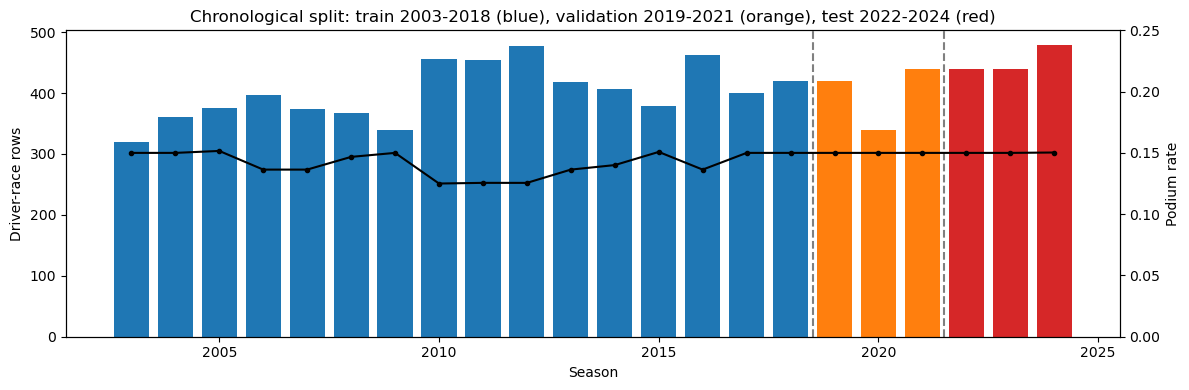

In [4]:
miss_by_split = pd.DataFrame({
    "train": train_df[FEATURES].isna().mean() * 100,
    "validation": val_df[FEATURES].isna().mean() * 100,
    "test": test_df[FEATURES].isna().mean() * 100,
}).round(2)
print("Missing values per feature and split (%):")
print(miss_by_split[miss_by_split.max(axis=1) > 0].to_string())

per_season = df.groupby("race_year").agg(rows=(TARGET, "size"), podium_rate=(TARGET, "mean"))
colors = ["tab:blue" if y <= TRAIN_YEARS[1] else "tab:orange" if y <= VAL_YEARS[1] else "tab:red"
          for y in per_season.index]

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(per_season.index, per_season["rows"], color=colors)
ax1.set_ylabel("Driver-race rows")
ax1.set_xlabel("Season")
ax2 = ax1.twinx()
ax2.plot(per_season.index, per_season["podium_rate"], color="black", marker="o", markersize=3)
ax2.set_ylabel("Podium rate")
ax2.set_ylim(0, 0.25)
ax1.axvline(TRAIN_YEARS[1] + 0.5, color="grey", linestyle="--")
ax1.axvline(VAL_YEARS[1] + 0.5, color="grey", linestyle="--")
plt.title("Chronological split: train 2003-2018 (blue), validation 2019-2021 (orange), test 2022-2024 (red)")
save_fig("20_m3_split_overview.png")

## 3. Metrics

**Primary metric: PR-AUC (average precision).** Only ~14% of rows are podiums, and ROC-AUC is dominated by the huge negative class: a model can look excellent on ROC-AUC while still ranking a midfield car above a front-row car. PR-AUC only rewards getting the positives ranked on top, which is exactly the product question ("which drivers have a realistic shot at the podium?").

**Secondary metric: F1 at a tuned threshold.** Reported because the brief requires a thresholded metric. The threshold is chosen on the validation split by maximising F1, never on test. We report the threshold itself so the number is reproducible.

**Reference metrics:** ROC-AUC (required by the brief, and comparable to other teams), precision, recall, accuracy and the Brier score (calibration, which matters for Member 4's SHAP values on probabilities).

**Domain metric: top-3 hit rate.** Exactly three drivers finish on the podium in each race, so we also take the model's three highest-scored drivers per race and ask how many of them were right. It needs no threshold and it is the way a fan would judge the model.

In [5]:
def top3_hit_rate(race_ids, y_true, scores):
    d = pd.DataFrame({"race": race_ids, "y": y_true, "s": scores})
    picked = d.sort_values("s", ascending=False).groupby("race").head(3)
    hits = picked.groupby("race")["y"].sum()
    available = d.groupby("race")["y"].sum().clip(upper=3)
    available = available[available > 0]
    return float((hits.reindex(available.index).fillna(0) / available).mean())


def tune_threshold(y_true, scores, grid=np.arange(0.02, 0.985, 0.005)):
    f1s = [f1_score(y_true, (scores >= t).astype(int), zero_division=0) for t in grid]
    best = int(np.argmax(f1s))
    return float(grid[best]), float(f1s[best])


def evaluate(y_true, scores, threshold, race_ids=None):
    pred = (scores >= threshold).astype(int)
    out = {
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "f1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "accuracy": accuracy_score(y_true, pred),
        "brier": brier_score_loss(y_true, np.clip(scores, 0, 1)),
        "threshold": threshold,
    }
    if race_ids is not None:
        out["top3_hit_rate"] = top3_hit_rate(race_ids, y_true, scores)
    return out


# A no-skill reference: PR-AUC of a random model equals the positive rate, ROC-AUC equals 0.5.
print("No-skill PR-AUC - train / validation / test:",
      round(y_tr.mean(), 4), round(y_va.mean(), 4), round(y_te.mean(), 4))

No-skill PR-AUC - train / validation / test: 0.1405 0.15 0.1501


## 4. Preprocessing

Member 2 deliberately left the NaNs in place, because imputation is a fitted step and must only see training rows. This class is that fitted step. It is written by hand rather than as a sklearn `Pipeline` for two reasons: the preprocessing-*order* has to be a swappable parameter for the experiments in section 5, and the inference function in section 11 needs to report which fields it had to impute for a partially-missing record.

Steps, in the order they are applied when `order="impute_then_scale"`:

1. **Missing indicators** — a 0/1 column for every feature whose training missingness is above a threshold. This is not cosmetic: `drv_points_share` is missing exactly on season openers, so "missing" is a real, informative state, not a measurement error. Without the indicator, median imputation would tell the model a season opener looks like an average mid-season race.
2. **Optional `log1p`** on the skewed count features, to see whether it helps the linear model.
3. **Median imputation** for the numeric features, mode imputation for the binary flag.
4. **Standardisation** (z-score), needed by logistic regression and the neural network, harmless for the trees.

With `order="scale_then_impute"` steps 3 and 4 swap: the centre and spread are computed from the observed values only (NaN-aware), and the gaps are filled afterwards in the standardised space. Every statistic (`median`, `mean`, `std`, `mode`) is computed on the rows passed to `fit`, which is the training block and nothing else.

In [6]:
class Preprocessor:
    """Leakage-safe preprocessing. Every statistic is learned in fit() and only applied in transform()."""

    def __init__(self, features, binary_features=(), order="impute_then_scale",
                 add_indicators=True, log_features=(), indicator_min_missing=0.005):
        assert order in {"impute_then_scale", "scale_then_impute"}
        self.features = list(features)
        self.binary_features = [c for c in binary_features if c in self.features]
        self.order = order
        self.add_indicators = add_indicators
        self.log_features = [c for c in log_features if c in self.features]
        self.indicator_min_missing = indicator_min_missing

    def _apply_log(self, X):
        if not self.log_features:
            return X
        X = X.copy()
        for c in self.log_features:
            X[c] = np.log1p(X[c].clip(lower=0))
        return X

    def fit(self, X):
        X = X.reindex(columns=self.features).astype(float)
        self.numeric_ = [c for c in self.features if c not in self.binary_features]
        self.missing_rate_ = X.isna().mean()
        self.indicator_cols_ = ([c for c in self.features if self.missing_rate_[c] >= self.indicator_min_missing]
                                if self.add_indicators else [])
        Xl = self._apply_log(X)

        if self.order == "impute_then_scale":
            self.impute_values_ = Xl[self.numeric_].median()
            Xi = Xl[self.numeric_].fillna(self.impute_values_)
            self.center_ = Xi.mean()
            self.scale_ = Xi.std(ddof=0).replace(0, 1.0)
        else:  # scale_then_impute: statistics from observed values only, gaps filled afterwards
            self.center_ = Xl[self.numeric_].mean()
            self.scale_ = Xl[self.numeric_].std(ddof=0).replace(0, 1.0)
            Xs = (Xl[self.numeric_] - self.center_) / self.scale_
            self.impute_values_ = Xs.median()

        self.binary_fill_ = {c: (float(X[c].mode().iloc[0]) if X[c].notna().any() else 0.0)
                             for c in self.binary_features}
        self.out_features_ = list(self.features) + [c + "_missing" for c in self.indicator_cols_]
        self.fitted_rows_ = len(X)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).reindex(columns=self.features).astype(float)
        ind = pd.DataFrame({c + "_missing": X[c].isna().astype(float) for c in self.indicator_cols_},
                           index=X.index)
        Xl = self._apply_log(X)

        if self.order == "impute_then_scale":
            num = Xl[self.numeric_].fillna(self.impute_values_)
            num = (num - self.center_) / self.scale_
        else:
            num = (Xl[self.numeric_] - self.center_) / self.scale_
            num = num.fillna(self.impute_values_)

        out = pd.DataFrame(index=X.index, columns=self.features, dtype=float)
        out[self.numeric_] = num
        for c in self.binary_features:
            out[c] = X[c].fillna(self.binary_fill_[c])
        out = pd.concat([out, ind], axis=1)
        assert out.notna().all().all(), "preprocessing left NaNs behind"
        return out[self.out_features_]

    def fit_transform(self, X):
        return self.fit(X).transform(X)


LOG_FEATURES = ["drv_starts_before", "drv_wins_before", "drv_circuit_podiums_before"]


def make_matrices(cfg, feats=FEATURES, fit_df=None):
    """Fit a Preprocessor on `fit_df` (training rows by default) and transform all three splits."""
    fit_df = train_df if fit_df is None else fit_df
    pre = Preprocessor(feats, binary_features=[b for b in BINARY if b in feats], **cfg).fit(fit_df[feats])
    mats = {"train": pre.transform(train_df[feats]),
            "val": pre.transform(val_df[feats]),
            "test": pre.transform(test_df[feats])}
    return pre, mats

## 5. Preprocessing-order experiments

The brief asks for at least two preprocessing-order experiments. We run four real configurations plus two diagnostic ones, and we run them **before** choosing the final models, with two fixed cheap probes so the comparison is about preprocessing and nothing else:

- a **logistic regression** probe, which is sensitive to scaling, skew and imputation, and
- a **histogram gradient boosting** probe, which is invariant to any monotone transform of a feature, so for it only the imputation and the indicators can move the score.

| Config | What changes |
|---|---|
| A | median impute → standardise (indicators on) |
| B | standardise (observed-only statistics) → impute in the scaled space |
| C | median impute → standardise, **without** missing indicators |
| D | `log1p` on the skewed counts → median impute → standardise |
| E (diagnostic) | config A but the scaler/imputer fitted on **all** rows, including validation and test |
| F (diagnostic) | no preprocessing at all, raw NaNs fed to the tree model's native NaN handling |

E is not a candidate. It is the leakage control: it shows what we would have gained if leakage were allowed, so we can say how much the leakage-safe discipline costs us.

                 config   probe  leakage_safe  val_pr_auc  val_roc_auc  val_f1
    A_impute_then_scale  logreg          True      0.7216       0.9375  0.7246
    A_impute_then_scale hist_gb          True      0.6741       0.9284  0.7068
    B_scale_then_impute  logreg          True      0.7218       0.9376  0.7264
    B_scale_then_impute hist_gb          True      0.6741       0.9284  0.7068
C_no_missing_indicators  logreg          True      0.7151       0.9347  0.7212
C_no_missing_indicators hist_gb          True      0.6728       0.9282  0.7113
D_log_then_impute_scale  logreg          True      0.7088       0.9364  0.7246
D_log_then_impute_scale hist_gb          True      0.6741       0.9284  0.7068
E_LEAKY_fit_on_all_rows  logreg         False      0.7218       0.9376  0.7264
E_LEAKY_fit_on_all_rows hist_gb         False      0.6613       0.9269  0.6925
       F_raw_native_nan hist_gb          True      0.6804       0.9281  0.7016

Mean validation PR-AUC over the two probes:
config


<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


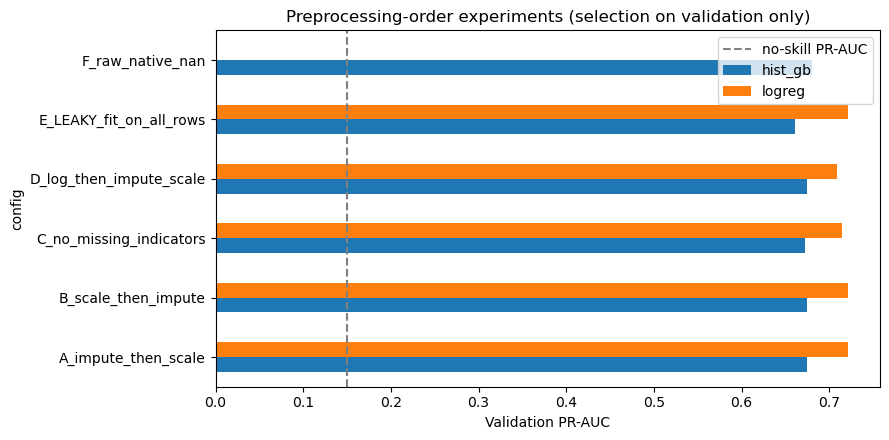

In [7]:
PRE_CONFIGS = {
    "A_impute_then_scale": dict(order="impute_then_scale", add_indicators=True, log_features=()),
    "B_scale_then_impute": dict(order="scale_then_impute", add_indicators=True, log_features=()),
    "C_no_missing_indicators": dict(order="impute_then_scale", add_indicators=False, log_features=()),
    "D_log_then_impute_scale": dict(order="impute_then_scale", add_indicators=True, log_features=LOG_FEATURES),
}

PROBES = {
    "logreg": lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED),
    "hist_gb": lambda: HistGradientBoostingClassifier(learning_rate=0.08, max_leaf_nodes=31, max_iter=300,
                                                      early_stopping=False, random_state=SEED),
}

pre_rows = []
for cfg_name, cfg in PRE_CONFIGS.items():
    _, mats = make_matrices(cfg)
    for probe_name, probe in PROBES.items():
        model = probe().fit(mats["train"], y_tr)
        s_va = model.predict_proba(mats["val"])[:, 1]
        thr, _ = tune_threshold(y_va, s_va)
        m = evaluate(y_va, s_va, thr, races_va)
        pre_rows.append({"config": cfg_name, "probe": probe_name, "leakage_safe": True,
                         "val_pr_auc": m["pr_auc"], "val_roc_auc": m["roc_auc"], "val_f1": m["f1"]})

# E - the leakage control: preprocessing statistics fitted on every row we have.
all_df = pd.concat([train_df, val_df, test_df])
for probe_name, probe in PROBES.items():
    _, mats = make_matrices(PRE_CONFIGS["A_impute_then_scale"], fit_df=all_df)
    model = probe().fit(mats["train"], y_tr)
    s_va = model.predict_proba(mats["val"])[:, 1]
    thr, _ = tune_threshold(y_va, s_va)
    m = evaluate(y_va, s_va, thr, races_va)
    pre_rows.append({"config": "E_LEAKY_fit_on_all_rows", "probe": probe_name, "leakage_safe": False,
                     "val_pr_auc": m["pr_auc"], "val_roc_auc": m["roc_auc"], "val_f1": m["f1"]})

# F - no preprocessing at all, native NaN handling (tree model only; logistic cannot accept NaNs).
raw_model = PROBES["hist_gb"]().fit(train_df[FEATURES], y_tr)
s_va = raw_model.predict_proba(val_df[FEATURES])[:, 1]
thr, _ = tune_threshold(y_va, s_va)
m = evaluate(y_va, s_va, thr, races_va)
pre_rows.append({"config": "F_raw_native_nan", "probe": "hist_gb", "leakage_safe": True,
                 "val_pr_auc": m["pr_auc"], "val_roc_auc": m["roc_auc"], "val_f1": m["f1"]})

pre_results = pd.DataFrame(pre_rows)
pre_results.to_csv(REPORT_DIR / "member3_preprocessing_experiments.csv", index=False)
print(pre_results.round(4).to_string(index=False))

candidates = pre_results[pre_results["config"].isin(PRE_CONFIGS)]
ranking = candidates.groupby("config")["val_pr_auc"].mean().sort_values(ascending=False)
print("\nMean validation PR-AUC over the two probes:")
print(ranking.round(4).to_string())
BEST_PRE_NAME = ranking.index[0]
BEST_PRE = PRE_CONFIGS[BEST_PRE_NAME]
print("\nChosen preprocessing:", BEST_PRE_NAME, BEST_PRE)

piv = pre_results.pivot_table(index="config", columns="probe", values="val_pr_auc")
ax = piv.plot(kind="barh", figsize=(9, 4.5))
ax.axvline(y_va.mean(), color="grey", linestyle="--", label="no-skill PR-AUC")
ax.set_xlabel("Validation PR-AUC")
ax.set_title("Preprocessing-order experiments (selection on validation only)")
ax.legend()
save_fig("21_m3_preprocessing_experiments.png")

### 5.1 Effect of the chosen preprocessing on the data

The checklist asks for the effect of the preprocessing step on the distribution, range and values of the data, so we show it directly: the same features before and after, plus a numeric summary.

Design matrix: (6407, 23) -> 23 columns (incl. missing indicators)
Missing indicators added: ['quali_gap_pct_missing', 'drv_podium_rate_last10_missing', 'drv_avg_finish_last10_missing', 'drv_dnf_rate_last10_missing', 'team_podium_rate_last10_missing', 'team_best_finish_last10_missing', 'drv_points_share_missing', 'team_points_share_missing']


<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


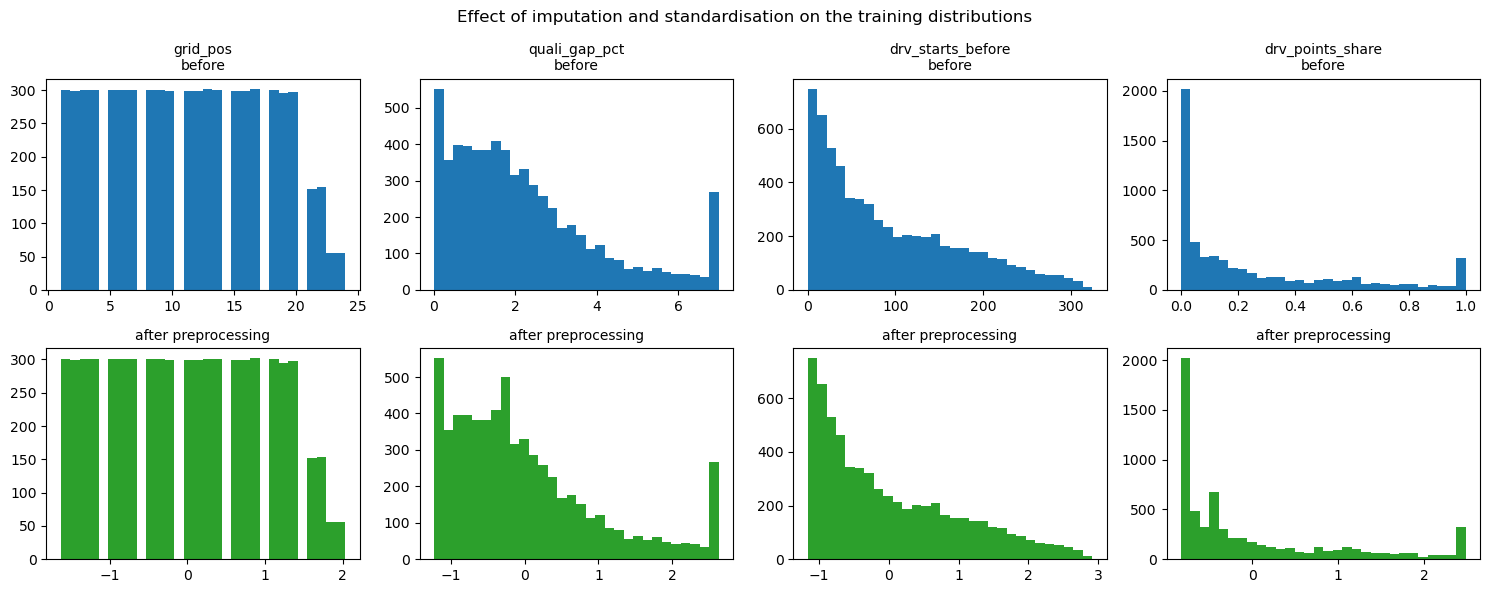

                            before_mean  before_std  before_min  before_max  before_missing_pct  after_mean  after_std  after_min  after_max  after_missing_pct
grid_pos                         11.244       6.264       1.000      24.000               0.000      -0.000      1.000     -1.635      2.037                0.0
grid_penalty                      0.042       0.200       0.000       1.000               0.328       0.042      0.199      0.000      1.000                0.0
quali_pos                        11.202       6.240       1.000      24.000               0.328      -0.000      0.998     -1.635      2.051                0.0
quali_gap_pct                     2.230       1.810       0.000       7.000               1.795      -0.004      0.992     -1.232      2.636                0.0
drv_podium_rate_last10            0.141       0.233       0.000       1.000               1.124      -0.007      0.996     -0.605      3.681                0.0
drv_avg_finish_last10            11.177 

In [8]:
PRE, MATS = make_matrices(BEST_PRE)
Xtr, Xva, Xte = MATS["train"], MATS["val"], MATS["test"]
FEATURE_NAMES = list(Xtr.columns)
print("Design matrix:", Xtr.shape, "->", len(FEATURE_NAMES), "columns (incl. missing indicators)")
print("Missing indicators added:", [c for c in FEATURE_NAMES if c.endswith("_missing")])

show = ["grid_pos", "quali_gap_pct", "drv_starts_before", "drv_points_share"]
fig, axes = plt.subplots(2, len(show), figsize=(15, 6))
for j, col in enumerate(show):
    axes[0, j].hist(train_df[col].dropna(), bins=30, color="tab:blue")
    axes[0, j].set_title(f"{col}\nbefore", fontsize=10)
    axes[1, j].hist(Xtr[col], bins=30, color="tab:green")
    axes[1, j].set_title("after preprocessing", fontsize=10)
fig.suptitle("Effect of imputation and standardisation on the training distributions")
save_fig("22_m3_preprocessing_effect.png")

effect = pd.DataFrame({
    "before_mean": train_df[FEATURES].mean(), "before_std": train_df[FEATURES].std(),
    "before_min": train_df[FEATURES].min(), "before_max": train_df[FEATURES].max(),
    "before_missing_pct": train_df[FEATURES].isna().mean() * 100,
    "after_mean": Xtr[FEATURES].mean(), "after_std": Xtr[FEATURES].std(),
    "after_min": Xtr[FEATURES].min(), "after_max": Xtr[FEATURES].max(),
    "after_missing_pct": Xtr[FEATURES].isna().mean() * 100,
}).round(3)
effect.to_csv(REPORT_DIR / "member3_preprocessing_effect.csv")
print(effect.to_string())

## 6. Baselines

A baseline is the reference point that tells us whether the complex models earn their complexity. We use two.

- **Majority class**: predict "no podium" for everyone. Accuracy ~86%, F1 = 0. It exists only to kill accuracy as a metric for this task.
- **Grid-position baseline**: score drivers purely by where they start, which is what a fan would do and which Member 2 showed is the single strongest feature (AUC ~0.91). The score is a monotone transform of the grid slot, so tuning the threshold on validation is equivalent to picking the best "podium if the driver starts in the top k" rule. Any model that cannot beat this is not worth training.

In [9]:
maj_scores_va = np.zeros(len(y_va))
print("Majority class - validation accuracy:", round(accuracy_score(y_va, maj_scores_va), 4),
      "| F1:", round(f1_score(y_va, maj_scores_va.astype(int), zero_division=0), 4))


def grid_baseline_scores(frame):
    return 1.0 - (frame["grid_pos"].clip(lower=1, upper=30).to_numpy() / 30.0)


base_tr, base_va, base_te = grid_baseline_scores(train_df), grid_baseline_scores(val_df), grid_baseline_scores(test_df)
BASE_THR, _ = tune_threshold(y_va, base_va)
implied_k = int(round((1 - BASE_THR) * 30))
print(f"Grid baseline threshold tuned on validation: {BASE_THR:.3f} -> rule 'podium if grid_pos <= {implied_k}'")

baseline_results = {
    "train": evaluate(y_tr, base_tr, BASE_THR, races_tr),
    "val": evaluate(y_va, base_va, BASE_THR, races_va),
    "test": evaluate(y_te, base_te, BASE_THR, races_te),
}
print(pd.DataFrame(baseline_results).T.round(4).to_string())

Majority class - validation accuracy: 0.85 | F1: 0.0
Grid baseline threshold tuned on validation: 0.870 -> rule 'podium if grid_pos <= 4'
       roc_auc  pr_auc      f1  precision  recall  accuracy   brier  threshold  top3_hit_rate
train   0.9071  0.6176  0.6381     0.6385  0.6378    0.8984  0.3288       0.87         0.6389
val     0.9169  0.6765  0.7167     0.7167  0.7167    0.9150  0.3423       0.87         0.7167
test    0.9138  0.6473  0.6486     0.6502  0.6471    0.8948  0.3429       0.87         0.6520


## 7. Models

Three families plus the baselines, all trained on exactly the same rows and the same design matrix, so the scores are directly comparable (a requirement of the brief).

- **Logistic regression** — linear, convex, fully interpretable coefficients. The natural statistical baseline above the grid rule, and the model whose assumptions the preprocessing in section 4 was designed for. *Limitation:* it can only draw a linear boundary in the feature space, while Member 2 showed the podium curve against grid slot is strongly non-linear (P1 ~79%, P3 ~50%, P8 ~5%), so it needs the standardised features to behave at all.
- **Random forest** — bagged trees, captures non-linearity and interactions, robust to the skewed count features. *Limitation:* it extrapolates badly to feature values outside the training range, and it tends to produce over-smoothed probabilities.
- **Histogram gradient boosting** — boosted trees, usually the strongest model on tabular data of this size. *Limitation:* more hyperparameters, and it can overfit the training seasons if the learning rate and leaf count are not controlled, which is exactly what the validation split is for.
- **Shallow feed-forward neural network** — one or two hidden layers as the brief specifies, ReLU, dropout, sigmoid output, binary cross-entropy. *Limitation:* the least data-efficient of the four on ~6k training rows, and sensitive to the scaling we apply in section 4.

The class imbalance (~14% positives) is handled in two ways: class weights inside each model where available, and a decision threshold tuned on validation for every model including those without class weights.

In [11]:
try:
    import tensorflow as tf
    from tensorflow import keras
    NN_BACKEND = "keras"
except Exception:
    NN_BACKEND = "sklearn"
print("Neural-network backend:", NN_BACKEND)


class ShallowNN:
    """Shallow feed-forward network (1-2 hidden layers) with a sklearn-style API.

    Uses Keras when TensorFlow is installed, and falls back to sklearn's MLPClassifier otherwise so
    the notebook stays run-all ready in either environment. The validation split is used only for
    early stopping and model selection - never the test split.
    """

    def __init__(self, hidden=(32,), dropout=0.2, lr=1e-3, l2=1e-4, epochs=200,
                 batch_size=256, balanced=True, patience=15, seed=SEED):
        self.hidden, self.dropout, self.lr, self.l2 = tuple(hidden), dropout, lr, l2
        self.epochs, self.batch_size, self.balanced, self.patience, self.seed = epochs, batch_size, balanced, patience, seed

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        if NN_BACKEND == "keras":
            keras.utils.set_random_seed(self.seed)
            model = keras.Sequential([keras.layers.Input(shape=(X.shape[1],))])
            for h in self.hidden:
                model.add(keras.layers.Dense(h, activation="relu",
                                             kernel_regularizer=keras.regularizers.l2(self.l2)))
                if self.dropout:
                    model.add(keras.layers.Dropout(self.dropout))
            model.add(keras.layers.Dense(1, activation="sigmoid"))
            model.compile(optimizer=keras.optimizers.Adam(self.lr), loss="binary_crossentropy",
                          metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])
            class_weight = None
            if self.balanced:
                n0, n1 = int((y == 0).sum()), int((y == 1).sum())
                class_weight = {0: len(y) / (2 * n0), 1: len(y) / (2 * n1)}
            callbacks, validation_data = [], None
            if X_val is not None:
                validation_data = (np.asarray(X_val, dtype=float), np.asarray(y_val, dtype=int))
                callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max",
                                                           patience=self.patience, restore_best_weights=True)]
            self.history_ = model.fit(X, y, validation_data=validation_data, epochs=self.epochs,
                                      batch_size=self.batch_size, class_weight=class_weight,
                                      callbacks=callbacks, verbose=0)
            self.model_ = model
            self.epochs_run_ = len(self.history_.history["loss"])
        else:
            self.model_ = MLPClassifier(hidden_layer_sizes=self.hidden, alpha=self.l2,
                                        learning_rate_init=self.lr, max_iter=self.epochs,
                                        batch_size=self.batch_size, early_stopping=True,
                                        n_iter_no_change=self.patience, validation_fraction=0.15,
                                        random_state=self.seed)
            self.model_.fit(X, y)
            self.epochs_run_ = self.model_.n_iter_
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if NN_BACKEND == "keras":
            p = self.model_.predict(X, verbose=0).ravel()
            return np.column_stack([1 - p, p])
        return self.model_.predict_proba(X)


def build_model(name, params):
    if name == "logistic_regression":
        return LogisticRegression(max_iter=3000, random_state=SEED, **params)
    if name == "random_forest":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    if name == "hist_gradient_boosting":
        return HistGradientBoostingClassifier(random_state=SEED, early_stopping=False, **params)
    if name == "shallow_nn":
        return ShallowNN(**params)
    raise ValueError(name)


def fit_model(name, params, X_train, y_train, X_val=None, y_val=None):
    model = build_model(name, params)
    if name == "shallow_nn":
        model.fit(X_train, y_train, X_val=X_val, y_val=y_val)
    else:
        model.fit(X_train, y_train)
    return model


def scores_of(model, X):
    return model.predict_proba(X)[:, 1]


MODEL_GRID = {
    "logistic_regression": [dict(C=c, class_weight=cw)
                            for c in [0.03, 0.1, 0.3, 1.0, 3.0] for cw in [None, "balanced"]],
    "random_forest": [dict(n_estimators=500, max_depth=d, min_samples_leaf=leaf, class_weight=cw)
                      for d in [None, 10] for leaf in [1, 10, 30] for cw in [None, "balanced_subsample"]],
    "hist_gradient_boosting": [dict(learning_rate=lr, max_leaf_nodes=leaves, max_iter=400, l2_regularization=l2)
                               for lr in [0.03, 0.08] for leaves in [15, 31] for l2 in [0.0, 1.0]],
    "shallow_nn": [dict(hidden=h, dropout=dr, lr=1e-3, epochs=200)
                   for h in [(16,), (32,), (64, 32)] for dr in [0.0, 0.2]],
}

Neural-network backend: sklearn


### 7.1 Hyperparameter search on validation

Every configuration is trained on the training split and scored on validation. The test split is not touched anywhere in this cell. We also record the training PR-AUC so the overfitting gap is visible for each configuration.

logistic_regression: 10 configurations trained
random_forest: 12 configurations trained
hist_gradient_boosting: 8 configurations trained
shallow_nn: 6 configurations trained
                family                config_id                                                                                                 params  train_pr_auc  val_pr_auc  val_roc_auc  val_f1  val_top3  threshold  overfit_gap
hist_gradient_boosting hist_gradient_boosting#0               {"learning_rate": 0.03, "max_leaf_nodes": 15, "max_iter": 400, "l2_regularization": 0.0}        0.9091      0.7372       0.9378  0.7337    0.7222      0.425       0.1718
hist_gradient_boosting hist_gradient_boosting#1               {"learning_rate": 0.03, "max_leaf_nodes": 15, "max_iter": 400, "l2_regularization": 1.0}        0.8948      0.7327       0.9390  0.7182    0.7167      0.445       0.1621
hist_gradient_boosting hist_gradient_boosting#3               {"learning_rate": 0.03, "max_leaf_nodes": 31, "max_iter": 400, "l2_r

<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


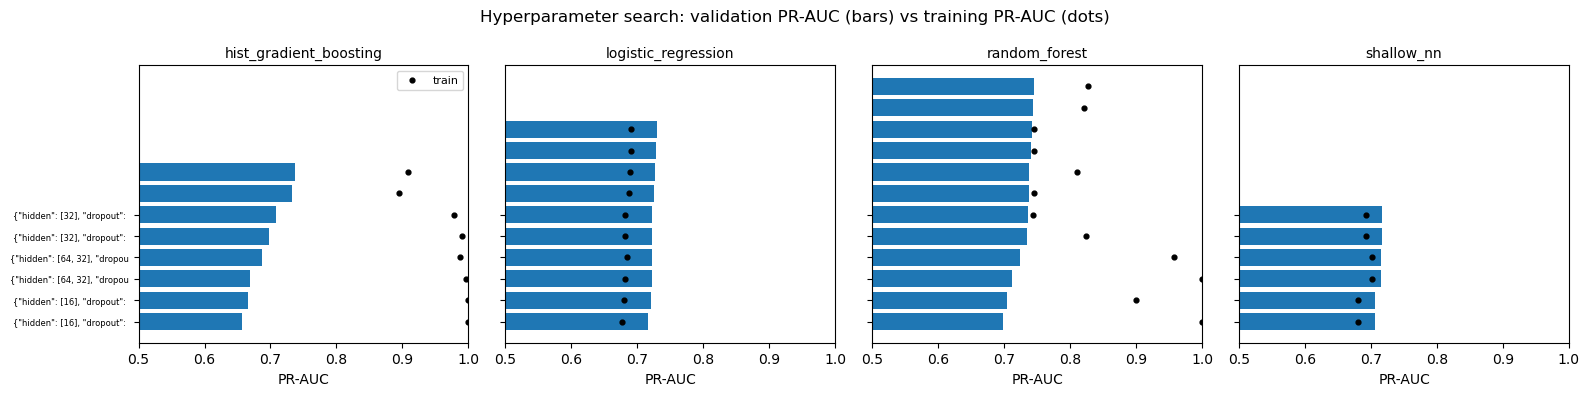

In [12]:
search_rows, fitted = [], {}
for family, grid in MODEL_GRID.items():
    for i, params in enumerate(grid):
        model = fit_model(family, params, Xtr, y_tr, Xva, y_va)
        s_tr, s_va = scores_of(model, Xtr), scores_of(model, Xva)
        thr, _ = tune_threshold(y_va, s_va)
        m_va = evaluate(y_va, s_va, thr, races_va)
        search_rows.append({
            "family": family, "config_id": f"{family}#{i}", "params": json.dumps(params, default=str),
            "train_pr_auc": average_precision_score(y_tr, s_tr),
            "val_pr_auc": m_va["pr_auc"], "val_roc_auc": m_va["roc_auc"], "val_f1": m_va["f1"],
            "val_top3": m_va["top3_hit_rate"], "threshold": thr,
            "overfit_gap": average_precision_score(y_tr, s_tr) - m_va["pr_auc"],
        })
        fitted[f"{family}#{i}"] = model
    print(f"{family}: {len(grid)} configurations trained")

search = pd.DataFrame(search_rows).sort_values(["family", "val_pr_auc"], ascending=[True, False])
search.to_csv(REPORT_DIR / "member3_hyperparameter_search.csv", index=False)
print(search.round(4).to_string(index=False))

best_per_family = search.loc[search.groupby("family")["val_pr_auc"].idxmax()].reset_index(drop=True)
print("\nBest configuration per family (selected on validation PR-AUC):")
print(best_per_family[["family", "params", "val_pr_auc", "val_roc_auc", "val_f1", "overfit_gap"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, len(MODEL_GRID), figsize=(16, 4), sharey=True)
for ax, (family, grp) in zip(axes, search.groupby("family")):
    grp = grp.sort_values("val_pr_auc")
    ax.barh(range(len(grp)), grp["val_pr_auc"], color="tab:blue")
    ax.scatter(grp["train_pr_auc"], range(len(grp)), color="black", s=12, label="train")
    ax.set_yticks(range(len(grp)), [p[:28] for p in grp["params"]], fontsize=6)
    ax.set_xlim(0.5, 1.0)
    ax.set_title(family, fontsize=10)
    ax.set_xlabel("PR-AUC")
axes[0].legend(fontsize=8)
fig.suptitle("Hyperparameter search: validation PR-AUC (bars) vs training PR-AUC (dots)")
save_fig("23_m3_hyperparameter_search.png")

## 8. Model comparison

For each family we take its validation-best configuration, tune the decision threshold on validation, and then report every metric on train, validation and the **unseen test set**. The test split is read here for the first time, and nothing after this point is selected using it.

In [13]:
FINAL_MODELS = {}
rows = []

for split, y_s, s_s, r_s in [("train", y_tr, base_tr, races_tr), ("validation", y_va, base_va, races_va),
                             ("test", y_te, base_te, races_te)]:
    rows.append({"model": "baseline_grid_position", "split": split, **evaluate(y_s, s_s, BASE_THR, r_s)})

for _, row in best_per_family.iterrows():
    family, cfg_id = row["family"], row["config_id"]
    model = fitted[cfg_id]
    FINAL_MODELS[family] = {"model": model, "params": json.loads(row["params"]), "config_id": cfg_id}
    s = {"train": scores_of(model, Xtr), "validation": scores_of(model, Xva), "test": scores_of(model, Xte)}
    thr, _ = tune_threshold(y_va, s["validation"])
    FINAL_MODELS[family]["threshold"] = thr
    FINAL_MODELS[family]["scores"] = s
    for split, y_s, r_s in [("train", y_tr, races_tr), ("validation", y_va, races_va), ("test", y_te, races_te)]:
        rows.append({"model": family, "split": split, **evaluate(y_s, s[split], thr, r_s)})

comparison = pd.DataFrame(rows)[
    ["model", "split", "roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy", "brier",
     "top3_hit_rate", "threshold"]
]
comparison.to_csv(REPORT_DIR / "member3_model_comparison.csv", index=False)
print(comparison.round(4).to_string(index=False))

print("\nValidation and test side by side (primary metric = PR-AUC):")
print(comparison[comparison["split"].isin(["validation", "test"])]
      .pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "f1"]).round(4).to_string())

# The model we hand to Member 4 is the one with the best validation PR-AUC, not the best test score.
# Choosing on test would make the test number meaningless.
BEST_FAMILY = best_per_family.loc[best_per_family["val_pr_auc"].idxmax(), "family"]
BEST = FINAL_MODELS[BEST_FAMILY]
BEST_THRESHOLD = BEST["threshold"]
print("\nSelected model:", BEST_FAMILY, BEST["params"], "| threshold:", round(BEST_THRESHOLD, 3))

                 model      split  roc_auc  pr_auc     f1  precision  recall  accuracy  brier  top3_hit_rate  threshold
baseline_grid_position      train   0.9071  0.6176 0.6381     0.6385  0.6378    0.8984 0.3288         0.6389      0.870
baseline_grid_position validation   0.9169  0.6765 0.7167     0.7167  0.7167    0.9150 0.3423         0.7167      0.870
baseline_grid_position       test   0.9138  0.6473 0.6486     0.6502  0.6471    0.8948 0.3429         0.6520      0.870
hist_gradient_boosting      train   0.9848  0.9091 0.8279     0.8000  0.8578    0.9499 0.0380         0.8278      0.425
hist_gradient_boosting validation   0.9378  0.7372 0.7337     0.7181  0.7500    0.9183 0.0636         0.7222      0.425
hist_gradient_boosting       test   0.9254  0.6384 0.6414     0.6615  0.6225    0.8955 0.0757         0.6225      0.425
   logistic_regression      train   0.9305  0.6902 0.6545     0.6319  0.6789    0.8993 0.0676         0.6511      0.405
   logistic_regression validation   0.93

### 8.1 Curves, confusion matrix and calibration

<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


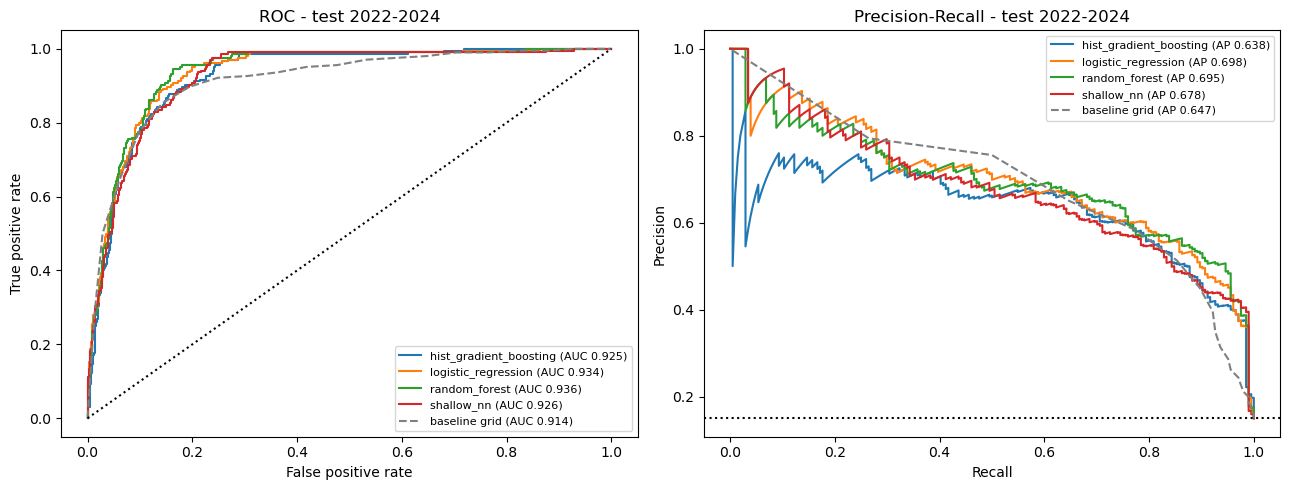

<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


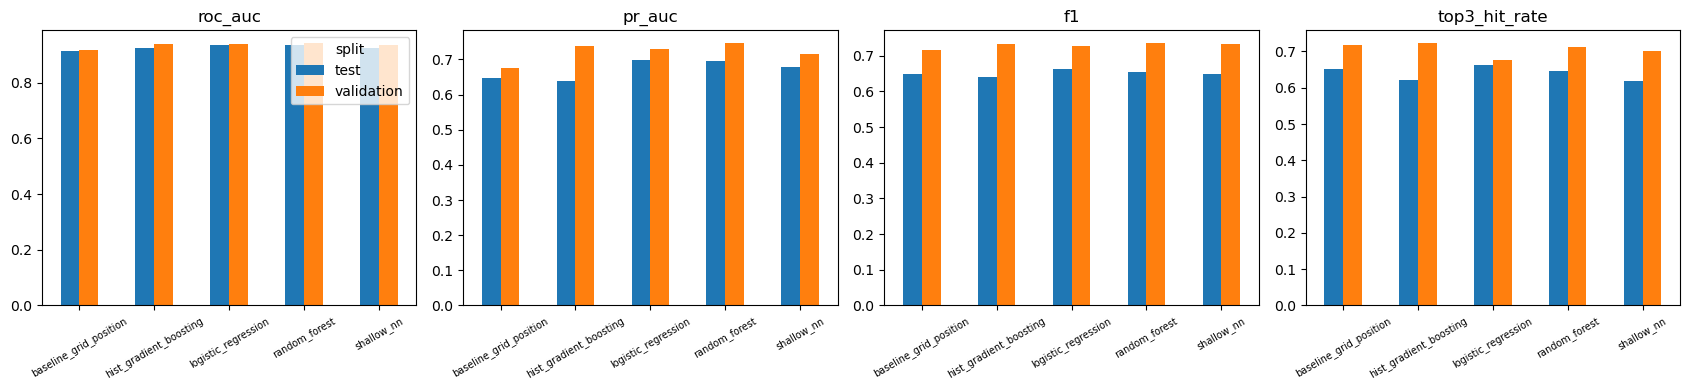

<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


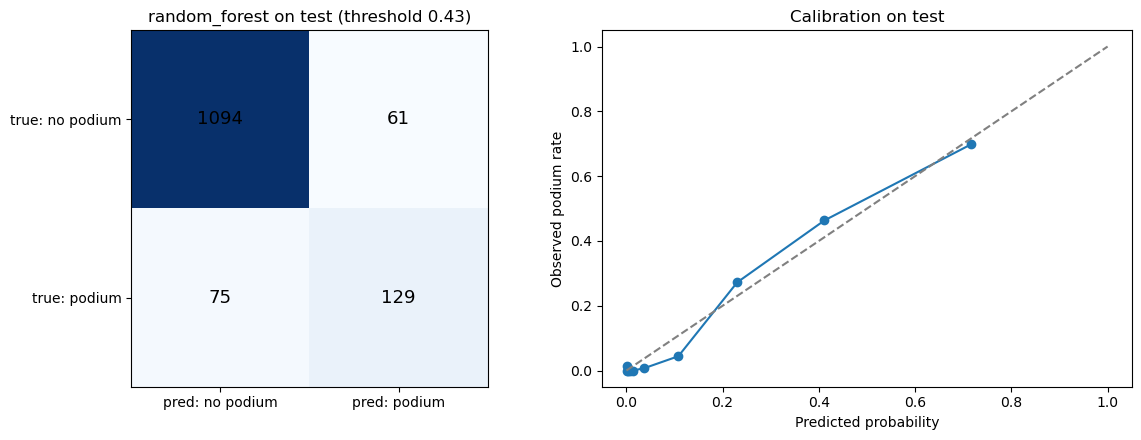

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for family, info in FINAL_MODELS.items():
    fpr, tpr, _ = roc_curve(y_te, info["scores"]["test"])
    axes[0].plot(fpr, tpr, label=f"{family} (AUC {roc_auc_score(y_te, info['scores']['test']):.3f})")
    prec, rec, _ = precision_recall_curve(y_te, info["scores"]["test"])
    axes[1].plot(rec, prec, label=f"{family} (AP {average_precision_score(y_te, info['scores']['test']):.3f})")
fpr, tpr, _ = roc_curve(y_te, base_te)
axes[0].plot(fpr, tpr, "--", color="grey", label=f"baseline grid (AUC {roc_auc_score(y_te, base_te):.3f})")
prec, rec, _ = precision_recall_curve(y_te, base_te)
axes[1].plot(rec, prec, "--", color="grey", label=f"baseline grid (AP {average_precision_score(y_te, base_te):.3f})")
axes[0].plot([0, 1], [0, 1], ":", color="black")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC - test 2022-2024")
axes[1].axhline(y_te.mean(), color="black", linestyle=":")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall - test 2022-2024")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
save_fig("24_m3_roc_pr_curves_test.png")

plot_metrics = ["roc_auc", "pr_auc", "f1", "top3_hit_rate"]
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(17, 4))
for ax, metric in zip(axes, plot_metrics):
    sub = comparison[comparison["split"].isin(["validation", "test"])].pivot(
        index="model", columns="split", values=metric)
    sub.plot(kind="bar", ax=ax, legend=(metric == plot_metrics[0]))
    ax.set_title(metric); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30, labelsize=7)
save_fig("25_m3_metric_comparison.png")

best_test = BEST["scores"]["test"]
cm = confusion_matrix(y_te, (best_test >= BEST_THRESHOLD).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f"{v}", ha="center", va="center", fontsize=13)
axes[0].set_xticks([0, 1], ["pred: no podium", "pred: podium"])
axes[0].set_yticks([0, 1], ["true: no podium", "true: podium"])
axes[0].set_title(f"{BEST_FAMILY} on test (threshold {BEST_THRESHOLD:.2f})")

prob_true, prob_pred = calibration_curve(y_te, np.clip(best_test, 0, 1), n_bins=10, strategy="quantile")
axes[1].plot(prob_pred, prob_true, marker="o")
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Observed podium rate")
axes[1].set_title("Calibration on test")
save_fig("26_m3_confusion_and_calibration.png")

### 8.2 Era sensitivity inside the test block

The test block spans the 2022 regulation reset and three very different competitive orders, so we break the test score down by season. This is the evidence behind the "era sensitivity" limitation in the report.

In [15]:
season_rows = []
for year, idx in test_df.groupby("race_year").groups.items():
    pos = test_df.index.get_indexer(idx)
    season_rows.append({"season": year, "rows": len(pos), "podium_rate": y_te[pos].mean(),
                        **evaluate(y_te[pos], best_test[pos], BEST_THRESHOLD, races_te[pos])})
season_test = pd.DataFrame(season_rows)
season_test.to_csv(REPORT_DIR / "member3_test_by_season.csv", index=False)
print(season_test.round(4).to_string(index=False))

 season  rows  podium_rate  roc_auc  pr_auc     f1  precision  recall  accuracy  brier  threshold  top3_hit_rate
   2022   440       0.1500   0.9432  0.6639 0.6718     0.6769  0.6667    0.9023 0.0698       0.43         0.6667
   2023   440       0.1500   0.9277  0.7587 0.6261     0.7347  0.5455    0.9023 0.0688       0.43         0.6364
   2024   479       0.1503   0.9320  0.6477 0.6622     0.6447  0.6806    0.8956 0.0715       0.43         0.6389


## 9. Feature-group ablation

An ablation removes one group of features at a time and retrains, so we can measure what each group actually contributes *after* training (Member 2's evidence justified the features *before* training; these two things are not the same and both are required).

The columns removed for each group come straight from `spec["ablation_drop"]`, so the definitions match Member 2's. Two details to defend:

- `grid_penalty` is dropped in the **qualifying** ablation as well, because it is derived from qualifying position.
- `grid_and_qualifying` removes both groups together. Member 2 measured a 0.97 correlation between them, so removing either on its own mostly measures redundancy, not importance. This combined run is the informative one.

Everything is retrained from scratch: a fresh `Preprocessor` fitted on the reduced training columns (so the imputation statistics match the reduced feature set) and the selected model family with its selected hyperparameters.

Ablation on the selected model (random_forest):
                ablation  n_features  val_pr_auc  test_pr_auc  delta_test_pr_auc  test_f1  delta_test_f1
 none (full feature set)          15      0.7457       0.6951             0.0000   0.6548         0.0000
               drop grid          13      0.7253       0.6816            -0.0135   0.6508        -0.0040
         drop qualifying          12      0.7282       0.6939            -0.0013   0.6482        -0.0066
               drop form          10      0.7424       0.7000             0.0049   0.6835         0.0287
          drop standings          12      0.7433       0.6788            -0.0163   0.6886         0.0338
         drop experience          12      0.7505       0.6896            -0.0055   0.6730         0.0182
drop grid_and_qualifying          11      0.6490       0.5774            -0.1177   0.5565        -0.0983


<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(FIG_DIR / name, dpi=160)
<ipython-input-1-96ee5aa4ab2c>:51: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(FIG_DIR / name, dpi=160)


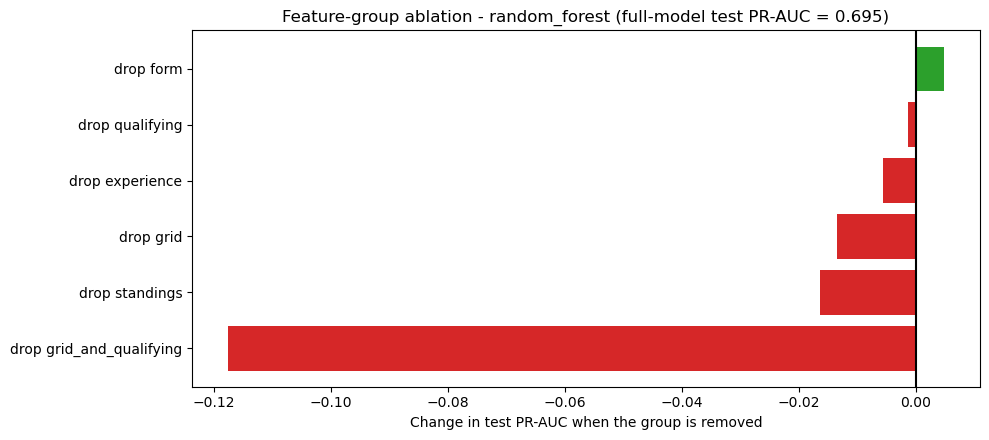

In [16]:
def run_ablation(drop_cols, family, params):
    feats = [f for f in FEATURES if f not in drop_cols]
    pre, mats = make_matrices(BEST_PRE, feats=feats)
    model = fit_model(family, params, mats["train"], y_tr, mats["val"], y_va)
    s_va, s_te = scores_of(model, mats["val"]), scores_of(model, mats["test"])
    thr, _ = tune_threshold(y_va, s_va)
    m_va = evaluate(y_va, s_va, thr, races_va)
    m_te = evaluate(y_te, s_te, thr, races_te)
    return {"n_features": len(feats),
            "val_pr_auc": m_va["pr_auc"], "val_roc_auc": m_va["roc_auc"], "val_f1": m_va["f1"],
            "test_pr_auc": m_te["pr_auc"], "test_roc_auc": m_te["roc_auc"], "test_f1": m_te["f1"],
            "test_top3": m_te["top3_hit_rate"]}


abl_rows = [{"ablation": "none (full feature set)", "dropped": "", **run_ablation([], BEST_FAMILY, BEST["params"])}]
for group, cols in ABLATION_DROP.items():
    abl_rows.append({"ablation": f"drop {group}", "dropped": ", ".join(cols),
                     **run_ablation(cols, BEST_FAMILY, BEST["params"])})

ablation = pd.DataFrame(abl_rows)
full = ablation.iloc[0]
for metric in ["val_pr_auc", "test_pr_auc", "test_roc_auc", "test_f1"]:
    ablation["delta_" + metric] = ablation[metric] - full[metric]
ablation.to_csv(REPORT_DIR / "member3_ablation.csv", index=False)
print(f"Ablation on the selected model ({BEST_FAMILY}):")
print(ablation[["ablation", "n_features", "val_pr_auc", "test_pr_auc", "delta_test_pr_auc",
                "test_f1", "delta_test_f1"]].round(4).to_string(index=False))

plot_abl = ablation.iloc[1:].sort_values("delta_test_pr_auc")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(plot_abl["ablation"], plot_abl["delta_test_pr_auc"],
        color=["tab:red" if v < 0 else "tab:green" for v in plot_abl["delta_test_pr_auc"]])
ax.axvline(0, color="black")
ax.set_xlabel("Change in test PR-AUC when the group is removed")
ax.set_title(f"Feature-group ablation - {BEST_FAMILY} (full-model test PR-AUC = {full['test_pr_auc']:.3f})")
save_fig("27_m3_ablation.png")

## 10. Sensitivity check: refitting on train + validation

Everything above trains on 2003-2018 only, so the validation numbers stay honest. Once the model and its hyperparameters are frozen, a practitioner would normally refit on train + validation to use the three extra seasons before predicting the future. We do that here as a **separate, clearly labelled** run and compare the test scores. The threshold is kept at the value tuned on validation (it cannot be retuned on the data the model now trains on, and it must not be tuned on test).

In [17]:
trval_df = pd.concat([train_df, val_df])
y_trval = trval_df[TARGET].to_numpy()
pre_trval = Preprocessor(FEATURES, binary_features=BINARY, **BEST_PRE).fit(trval_df[FEATURES])
X_trval, X_te_refit = pre_trval.transform(trval_df[FEATURES]), pre_trval.transform(test_df[FEATURES])
model_refit = fit_model(BEST_FAMILY, BEST["params"], X_trval, y_trval, X_te_refit[:0], y_te[:0]) \
    if BEST_FAMILY != "shallow_nn" else fit_model(BEST_FAMILY, BEST["params"], X_trval, y_trval)
s_te_refit = scores_of(model_refit, X_te_refit)

refit = pd.DataFrame([
    {"fit_on": "train 2003-2018 (reported model)", **evaluate(y_te, best_test, BEST_THRESHOLD, races_te)},
    {"fit_on": "train + validation 2003-2021", **evaluate(y_te, s_te_refit, BEST_THRESHOLD, races_te)},
])
refit.to_csv(REPORT_DIR / "member3_refit_sensitivity.csv", index=False)
print(refit.round(4).to_string(index=False))
print("\nNote: the headline numbers in the report are the train-only model. This refit is a sensitivity "
      "check, not the reported result, because its validation score no longer exists.")

                          fit_on  roc_auc  pr_auc     f1  precision  recall  accuracy  brier  threshold  top3_hit_rate
train 2003-2018 (reported model)   0.9362  0.6951 0.6548     0.6789  0.6324    0.8999 0.0701       0.43         0.6471
    train + validation 2003-2021   0.9361  0.6803 0.6500     0.6633  0.6373    0.8970 0.0705       0.43         0.6520

Note: the headline numbers in the report are the train-only model. This refit is a sensitivity check, not the reported result, because its validation score no longer exists.


## 11. Inference function

One function that takes a raw driver-race record (a dict, a list of dicts, or a DataFrame), applies the preprocessing fitted on the training split, and returns the podium probability, the decision at the validation-tuned threshold, and which fields had to be imputed. Missing fields are allowed by design: at the real cutoff a driver can have no qualifying record, or it can be round 1 with no standings yet. The function reports them instead of failing, because the honest answer is a prediction plus a note on what was unknown.

In [18]:
INFERENCE_BUNDLE = {"preprocessor": PRE, "model": BEST["model"], "threshold": BEST_THRESHOLD,
                    "features": FEATURES, "family": BEST_FAMILY}


def predict_podium(records, bundle=INFERENCE_BUNDLE, return_inputs=False):
    """Predict podium probability for one or more driver-race records available at the pre-race cutoff."""
    if isinstance(records, dict):
        records = [records]
    X_raw = pd.DataFrame(records).copy() if not isinstance(records, pd.DataFrame) else records.copy()
    X_raw = X_raw.reset_index(drop=True)

    feats = bundle["features"]
    supplied = [c for c in feats if c in X_raw.columns]
    unknown = [c for c in X_raw.columns if c not in feats and c not in ID_COLS]
    X_raw = X_raw.reindex(columns=sorted(set(X_raw.columns) | set(feats)))

    Xp = bundle["preprocessor"].transform(X_raw[feats])
    proba = bundle["model"].predict_proba(Xp)[:, 1]

    missing_lists = [[c for c in feats if pd.isna(X_raw.loc[i, c])] for i in X_raw.index]
    out = pd.DataFrame({
        "podium_probability": np.round(proba, 4),
        "predicted_podium": (proba >= bundle["threshold"]).astype(int),
        "threshold": bundle["threshold"],
        "n_features_imputed": [len(m) for m in missing_lists],
        "imputed_features": [", ".join(m) if m else "none" for m in missing_lists],
    })
    if unknown:
        out.attrs["ignored_columns"] = unknown
    if return_inputs:
        return out, Xp
    return out

### 11.1 Demonstration on a complete record

We take a real test-season row (unseen by the model) and compare the prediction with the truth.

In [19]:
complete_idx = test_df.index[(test_df["grid_pos"] <= 3) & (test_df["race_year"] == 2023)][0]
complete_record = test_df.loc[complete_idx, FEATURES].to_dict()
print("Complete record (2023, front-row starter):")
print(pd.Series(complete_record).round(3).to_string())
print("\nPrediction:")
print(predict_podium(complete_record).to_string(index=False))
print("Actual podium:", int(test_df.loc[complete_idx, TARGET]))

Complete record (2023, front-row starter):
grid_pos                        2.000
grid_penalty                    0.000
quali_pos                       2.000
quali_gap_pct                   0.154
drv_podium_rate_last10          0.500
drv_avg_finish_last10           3.800
drv_dnf_rate_last10             0.000
team_podium_rate_last10         0.650
team_best_finish_last10         1.500
drv_points_share                  NaN
drv_wins_before                 0.000
team_points_share                 NaN
drv_starts_before             237.000
drv_age                        33.103
drv_circuit_podiums_before      2.000

Prediction:
 podium_probability  predicted_podium  threshold  n_features_imputed                    imputed_features
             0.6662                 1       0.43                   2 drv_points_share, team_points_share
Actual podium: 1


### 11.2 Demonstration on a partially-missing record

The same driver-race, but as it would look at the cutoff of a **season opener where the driver has no qualifying record**: no `quali_pos`, no `quali_gap_pct`, no `grid_penalty` (all derived from qualifying) and no standings shares (round 1 has no previous round). Member 2's missingness analysis says these are exactly the gaps that occur in practice.

In [20]:
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ["quali_pos", "quali_gap_pct", "grid_penalty",
                               "drv_points_share", "team_points_share"]}
print("Partially-missing record (season opener, no qualifying record):")
print(pd.Series(partial_record).round(3).to_string())
print("\nPrediction:")
print(predict_podium(partial_record).to_string(index=False))

Partially-missing record (season opener, no qualifying record):
grid_pos                        2.000
drv_podium_rate_last10          0.500
drv_avg_finish_last10           3.800
drv_dnf_rate_last10             0.000
team_podium_rate_last10         0.650
team_best_finish_last10         1.500
drv_wins_before                 0.000
drv_starts_before             237.000
drv_age                        33.103
drv_circuit_podiums_before      2.000

Prediction:
 podium_probability  predicted_podium  threshold  n_features_imputed                                                            imputed_features
             0.3659                 0       0.43                   5 grid_penalty, quali_pos, quali_gap_pct, drv_points_share, team_points_share


### 11.3 A hand-written record and a small batch

A record typed from scratch, to show the function does not depend on the modeling table, plus a batch call on a whole race so the output can be ranked the way the podium actually works.

In [21]:
hand_written = {
    "grid_pos": 1, "grid_penalty": 0, "quali_pos": 1, "quali_gap_pct": 0.0,
    "drv_podium_rate_last10": 0.8, "drv_avg_finish_last10": 2.1, "drv_dnf_rate_last10": 0.1,
    "team_podium_rate_last10": 0.75, "team_best_finish_last10": 1.6,
    "drv_points_share": 1.0, "drv_wins_before": 6, "team_points_share": 1.0,
    "drv_starts_before": 150, "drv_age": 27.5, "drv_circuit_podiums_before": 3,
}
print(predict_podium([hand_written, partial_record]).to_string(index=False))

one_race = test_df[test_df["raceId"] == test_df["raceId"].iloc[-1]]
race_pred = predict_podium(one_race[FEATURES])
race_pred["driverId"] = one_race["driverId"].to_numpy()
race_pred["actual_podium"] = one_race[TARGET].to_numpy()
print("\nFull grid of one test race, ranked by predicted probability:")
print(race_pred.sort_values("podium_probability", ascending=False)
      [["driverId", "podium_probability", "predicted_podium", "actual_podium", "n_features_imputed"]]
      .head(8).to_string(index=False))

 podium_probability  predicted_podium  threshold  n_features_imputed                                                            imputed_features
             0.8940                 1       0.43                   0                                                                        none
             0.3659                 0       0.43                   5 grid_penalty, quali_pos, quali_gap_pct, drv_points_share, team_points_share

Full grid of one test race, ranked by predicted probability:
 driverId  podium_probability  predicted_podium  actual_podium  n_features_imputed
      846              0.7895                 1              1                   0
      857              0.6346                 1              0                   0
      830              0.5616                 1              0                   0
      832              0.4886                 1              1                   0
      844              0.2310                 0              1                   0
     

## 12. Export for Member 4 (XAI)

Member 4 needs the exact objects the scores above came from, otherwise their SHAP values explain a different model from the one we reported. We export:

- the fitted preprocessing + model bundle and the decision threshold,
- the **processed** design matrices with their column names, which is what permutation importance, SHAP and LIME have to be run on (the raw table would give explanations for columns the model never saw, and LIME needs the training matrix to build its local neighbourhood),
- the test predictions, so local explanations can be picked for interesting rows,
- a JSON handoff with the split, the selected configuration and the headline metrics.

The best tree model is saved separately even if it is not the selected model, because SHAP's fast `TreeExplainer` only works on tree ensembles; a Keras network needs `KernelExplainer` or `DeepExplainer` instead.

In [22]:
for split_name, X_split, frame, y_split in [("train", Xtr, train_df, y_tr),
                                            ("val", Xva, val_df, y_va),
                                            ("test", Xte, test_df, y_te)]:
    out = pd.concat([frame[ID_COLS].reset_index(drop=True), X_split.reset_index(drop=True)], axis=1)
    out[TARGET] = y_split
    out.to_csv(MODEL_DIR / f"member3_design_matrix_{split_name}.csv", index=False)

test_predictions = test_df[ID_COLS + ["grid_pos", "quali_pos"]].reset_index(drop=True)
test_predictions["podium"] = y_te
test_predictions["podium_probability"] = best_test
test_predictions["predicted_podium"] = (best_test >= BEST_THRESHOLD).astype(int)
test_predictions.to_csv(REPORT_DIR / "member3_test_predictions.csv", index=False)

tree_family = "hist_gradient_boosting" if "hist_gradient_boosting" in FINAL_MODELS else "random_forest"
try:
    joblib.dump({"preprocessor": PRE, "model": BEST["model"], "threshold": BEST_THRESHOLD,
                 "family": BEST_FAMILY, "features": FEATURES, "matrix_columns": FEATURE_NAMES},
                MODEL_DIR / "member3_best_model.joblib")
    print("Saved:", MODEL_DIR / "member3_best_model.joblib")
except Exception as exc:  # a Keras model is not joblib-serialisable on every backend
    print("Could not joblib the selected model:", exc)
    if NN_BACKEND == "keras" and isinstance(BEST["model"], ShallowNN):
        BEST["model"].model_.save(MODEL_DIR / "member3_best_nn.keras")
        print("Saved the network separately as member3_best_nn.keras")

joblib.dump({"preprocessor": PRE, "model": FINAL_MODELS[tree_family]["model"],
             "threshold": FINAL_MODELS[tree_family]["threshold"], "family": tree_family,
             "features": FEATURES, "matrix_columns": FEATURE_NAMES},
            MODEL_DIR / "member3_tree_model_for_shap.joblib")

handoff = {
    "split": {"train": list(TRAIN_YEARS), "validation": list(VAL_YEARS), "test": list(TEST_YEARS)},
    "preprocessing": {"name": BEST_PRE_NAME, **{k: list(v) if isinstance(v, (list, tuple)) else v
                                                for k, v in BEST_PRE.items()}},
    "matrix_columns": FEATURE_NAMES,
    "selected_model": {"family": BEST_FAMILY, "params": BEST["params"], "threshold": BEST_THRESHOLD},
    "tree_model_for_shap": {"family": tree_family, "params": FINAL_MODELS[tree_family]["params"]},
    "primary_metric": "pr_auc",
    "secondary_metric": "f1_at_validation_tuned_threshold",
    "nn_backend": NN_BACKEND,
    "headline": comparison[(comparison["model"] == BEST_FAMILY)]
                .set_index("split")[["roc_auc", "pr_auc", "f1", "precision", "recall", "top3_hit_rate"]]
                .round(4).to_dict(orient="index"),
}
(MODEL_DIR / "member3_handoff.json").write_text(json.dumps(handoff, indent=2, default=str), encoding="utf-8")
print(json.dumps(handoff["headline"], indent=2))

Saved: /drive/notebooks/MS1/data/models/member3_best_model.joblib
{
  "train": {
    "roc_auc": 0.9668,
    "pr_auc": 0.8276,
    "f1": 0.7345,
    "precision": 0.739,
    "recall": 0.73,
    "top3_hit_rate": 0.7344
  },
  "validation": {
    "roc_auc": 0.941,
    "pr_auc": 0.7457,
    "f1": 0.7342,
    "precision": 0.7243,
    "recall": 0.7444,
    "top3_hit_rate": 0.7111
  },
  "test": {
    "roc_auc": 0.9362,
    "pr_auc": 0.6951,
    "f1": 0.6548,
    "precision": 0.6789,
    "recall": 0.6324,
    "top3_hit_rate": 0.6471
  }
}


## 13. Notes for Member 4 and known limitations

**How to load.** `joblib.load("data/models/member3_best_model.joblib")` gives `preprocessor`, `model`, `threshold` and `matrix_columns`. Run permutation importance, SHAP and LIME on `data/models/member3_design_matrix_*.csv` (drop the id columns and `podium`), never on the raw modeling table: the model was trained on the standardised matrix plus the missing indicators, and the column order in `matrix_columns` is the order the model expects.

**Which model to explain.** Explain the selected model for the headline, and use `member3_tree_model_for_shap.joblib` if `TreeExplainer` is needed for speed. If both are explained, say in the report which figure belongs to which model.

**Causality warning for the report.** Permutation importance and SHAP measure what the *model* relies on, not what *causes* a podium. `grid_pos` dominating does not prove that starting on the front row causes podiums; grid position is itself a consequence of car pace, which also causes the result. Member 2's Q2 is the clean example: the unadjusted home-race rate looks like an effect and disappears once grid position is controlled for.

**Known limitations of this stage.**

- **Era shift.** The test block is the 2022 ground-effect era, which no training season covers. The per-season test breakdown in 8.2 quantifies how much that costs.
- **Correlated groups.** Grid and qualifying correlate at 0.97, so the single-group ablations understate their joint contribution and permutation importance will split credit between them arbitrarily. The `grid_and_qualifying` row is the one to quote.
- **Validation reused.** The validation split sets the preprocessing, the hyperparameters, the neural network's early stopping and the threshold. Its scores are therefore mildly optimistic; the test scores are not.
- **Three podiums per race.** The models score each driver independently, so nothing stops them predicting five podiums in one race. The top-3 hit rate measures the race-level view; a per-race ranking model would be the natural next step and is out of scope for this milestone.
- **Imputation of season openers.** Round-1 rows get a median points share plus a missing indicator. That is a modelling convention, not a fact about those races.